<a href="https://colab.research.google.com/github/Lorenzo-v8/Machine-Learning-Clasificacion-de-Alubias/blob/main/Clasificacion_de_alubias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de porotos secos (Dry Beans): QDA, SVM, PCA, Naive Bayes y LDA

**Objetivo:** predecir el tipo de poroto (`Class`) a partir de 16 medidas de forma y tamaño, y comparar cinco técnicas.

**Criterios del trabajo**
- Los registros duplicados se analizan pero no se eliminan.
- Todo el preprocesamiento (estandarización y PCA) se ajusta **solo con los datos de entrenamiento** para evitar fuga de información.
- Se usa siempre la misma partición entrenamiento/prueba para que los modelos sean comparables.




## 1. Importación de librerías


In [ ]:
# Importamos todas las librerías una sola vez, al principio del notebook
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler            # pone las variables en la misma escala
from sklearn.decomposition import PCA                       # reducción de dimensiones
from sklearn.pipeline import Pipeline                       # encadena preprocesamiento + modelo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB                  # Naive Bayes (NB)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis  # LDA y QDA
from sklearn.svm import SVC                                 # Support Vector Machine (SVM)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

# Estilo de gráficos uniforme para todo
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90


## 2. Carga del dataset


In [ ]:
# Buscamos el archivo Excel en la carpeta de trabajo
archivos = glob.glob("base*datos*parcial*.xlsx")

# Si no está (por ejemplo, en Google Colab recién abierto), lo subimos a mano
if not archivos:
    from google.colab import files
    files.upload()
    archivos = glob.glob("base*datos*parcial*.xlsx")

# Si hay varios, usamos el más reciente
archivo = max(archivos, key=os.path.getmtime)
print("Leyendo:", archivo)

df = pd.read_excel(archivo, sheet_name="Dry_Beans_Dataset")
df.head()


Saving base de datos parcial.xlsx to base de datos parcial.xlsx
Leyendo: base de datos parcial.xlsx


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Exploración inicial de los datos


In [ ]:
# Tamaño de la tabla, tipos de dato y estadísticos descriptivos de cada variable
print("Filas y columnas:", df.shape)
df.info()
display(df.describe().T.round(3))


Filas y columnas: (13611, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-n

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRation,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


## 4. Análisis de valores faltantes (NA)


In [ ]:
# Contamos los valores faltantes de cada columna y su porcentaje
na = pd.DataFrame({"NA": df.isna().sum(), "% NA": (df.isna().mean() * 100).round(2)})
display(na)
print("Total de NA en la base:", int(df.isna().sum().sum()))

# Otros "faltantes escondidos": infinitos en las variables numéricas y etiquetas vacías en Class
print("Valores infinitos:", int(np.isinf(df.drop(columns="Class")).sum().sum()))
print("Etiquetas de clase vacías:", int((df["Class"].astype(str).str.strip() == "").sum()))


,NA,% NA
Area,0,0.0
Perimeter,0,0.0
MajorAxisLength,0,0.0
MinorAxisLength,0,0.0
AspectRation,0,0.0
Eccentricity,0,0.0
ConvexArea,0,0.0
EquivDiameter,0,0.0
Extent,0,0.0
Solidity,0,0.0


Total de NA en la base: 0
Valores infinitos: 0
Etiquetas de clase vacías: 0


## 5. Análisis de duplicados


Copias duplicadas: 68 (0.50% de la base)


,Duplicados,Total de la clase,% de la clase
Class,,,
BARBUNYA,0,1322,0.00
BOMBAY,0,522,0.00
CALI,0,1630,0.00
DERMASON,0,3546,0.00
HOROZ,68,1928,3.53
SEKER,0,2027,0.00
SIRA,0,2636,0.00


Posición de los duplicados en el archivo: filas 5505 a 7342
Combinaciones de medidas con clases distintas: 0


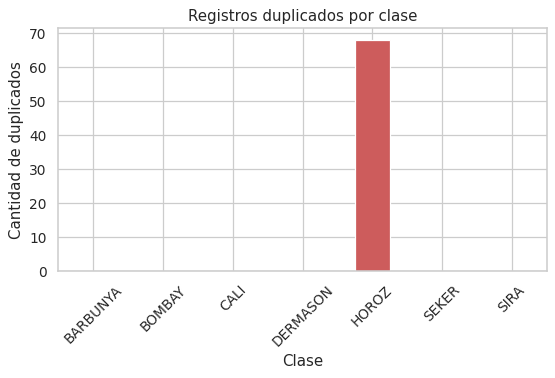

In [ ]:
variables = [c for c in df.columns if c != "Class"]

dup = df.duplicated()
print(f"Copias duplicadas: {dup.sum()} ({dup.mean() * 100:.2f}% de la base)")

# ¿En qué clases están y en qué parte del archivo?
por_clase = pd.DataFrame({"Duplicados": df[dup]["Class"].value_counts(),
                          "Total de la clase": df["Class"].value_counts()}).fillna(0).astype(int)
por_clase["% de la clase"] = (por_clase["Duplicados"] / por_clase["Total de la clase"] * 100).round(2)
display(por_clase)
print("Posición de los duplicados en el archivo: filas", df.index[dup].min(), "a", df.index[dup].max())

# ¿Hay filas con las mismas medidas pero distinta clase?
conflictos = int((df.groupby(variables)["Class"].nunique() > 1).sum())
print("Combinaciones de medidas con clases distintas:", conflictos)

# Gráfico: cantidad de duplicados por clase
por_clase["Duplicados"].plot(kind="bar", color="indianred", figsize=(7, 3.5))
plt.title("Registros duplicados por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad de duplicados")
plt.xticks(rotation=45)
plt.show()

## 6. Análisis del balance de clases


,Cantidad,Porcentaje (%)
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


Clase mayor (DERMASON) vs clase menor (BOMBAY): 6.8 a 1


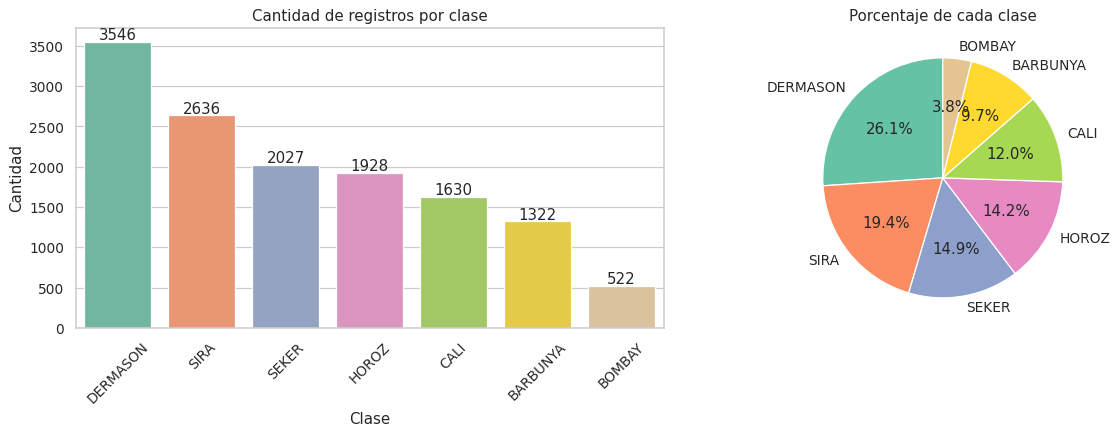

In [ ]:
# Cantidad y porcentaje de registros de cada clase
conteo = df["Class"].value_counts()
balance = pd.DataFrame({"Cantidad": conteo, "Porcentaje (%)": (conteo / len(df) * 100).round(2)})
display(balance)
print(f"Clase mayor ({conteo.idxmax()}) vs clase menor ({conteo.idxmin()}): {conteo.max() / conteo.min():.1f} a 1")

# Gráficos: barras con la cantidad y torta con el porcentaje de cada clase
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette="Set2", legend=False, ax=ax[0])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v + 30, str(v), ha="center")
ax[0].set_title("Cantidad de registros por clase")
ax[0].set_xlabel("Clase")
ax[0].set_ylabel("Cantidad")
ax[0].tick_params(axis="x", rotation=45)

ax[1].pie(conteo.values, labels=conteo.index, autopct="%1.1f%%", colors=sns.color_palette("Set2", len(conteo)), startangle=90)
ax[1].set_title("Porcentaje de cada clase")

plt.tight_layout()
plt.show()


**Conclusión:** el dataset está **desbalanceado de forma moderada**: DERMASON es la clase más grande (26 %) y BOMBAY la más chica (3,8 %), una relación de casi 7 a 1.

**Posibles consecuencias:**
- La *accuracy* puede esconder malos resultados en las clases chicas, porque las clases grandes pesan más en el promedio.
- Los modelos que usan la frecuencia de cada clase (NB, LDA y QDA) tienden a favorecer a las clases más frecuentes.

**Decisión:** no se aplica ninguna técnica de balanceo. El desbalance es moderado, ninguna clase tiene pocos ejemplos (la menor tiene más de 500) y los cinco modelos se comparan con la misma partición. Para controlar el efecto se usa una partición **estratificada** (mantiene las proporciones) y se informan métricas **macro** (promedian todas las clases por igual) y el *recall* de cada clase.


## 7. Análisis exploratorio y visualizaciones


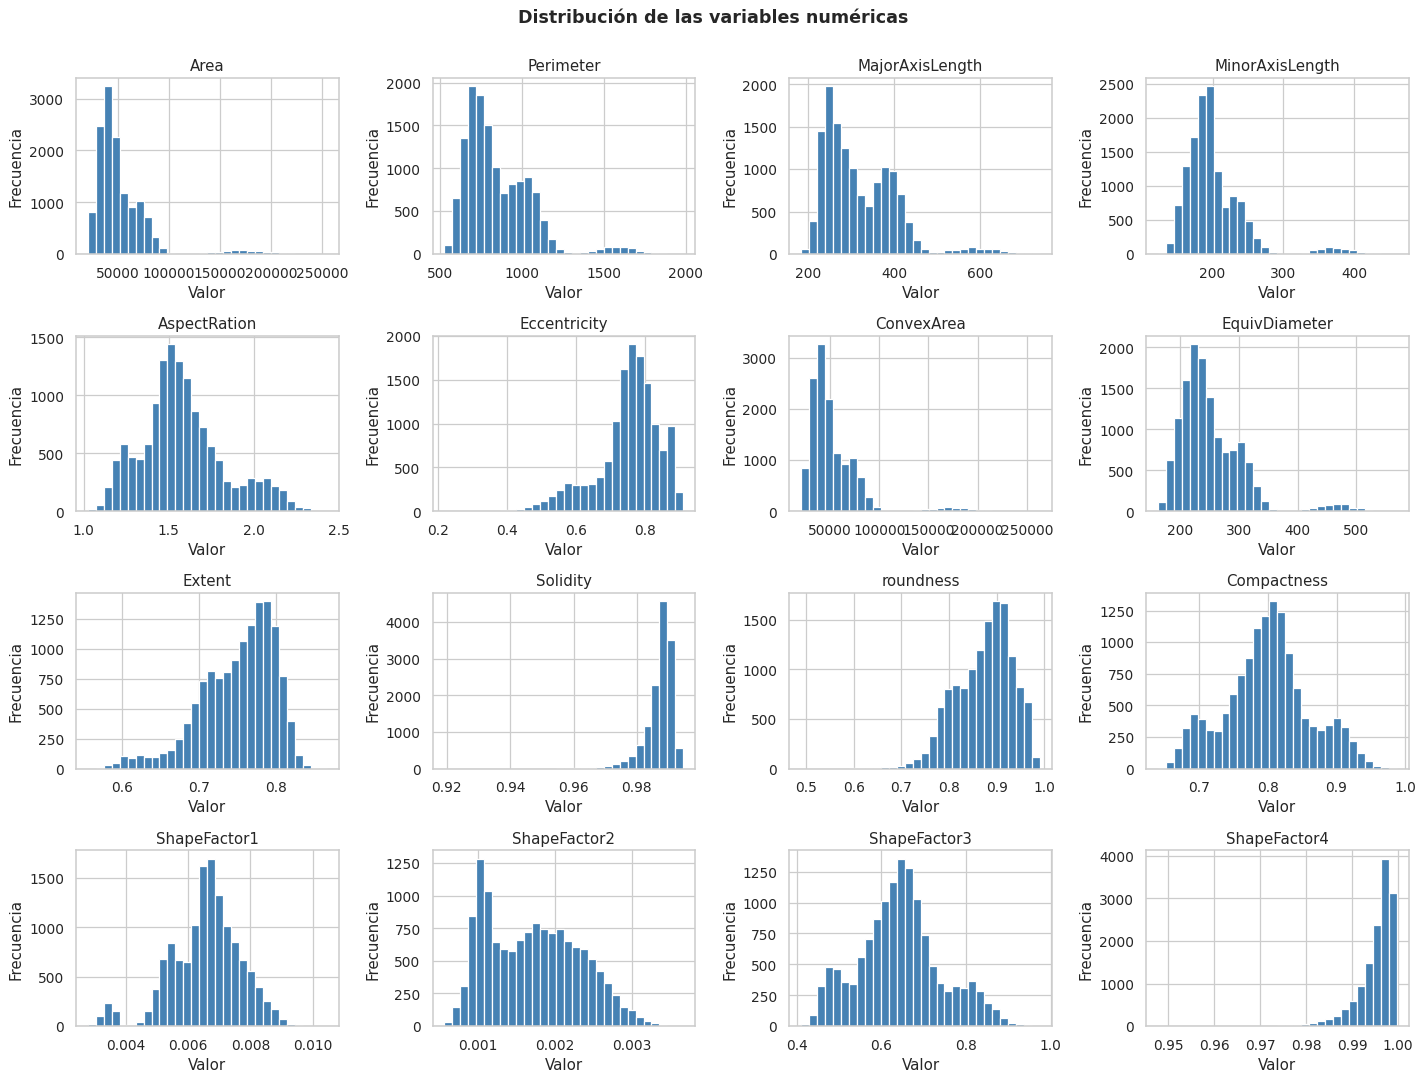

In [ ]:
# Distribución de cada variable numérica (16 histogramas)
variables_num = df.drop(columns="Class").columns
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), variables_num):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")
plt.suptitle("Distribución de las variables numéricas", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()


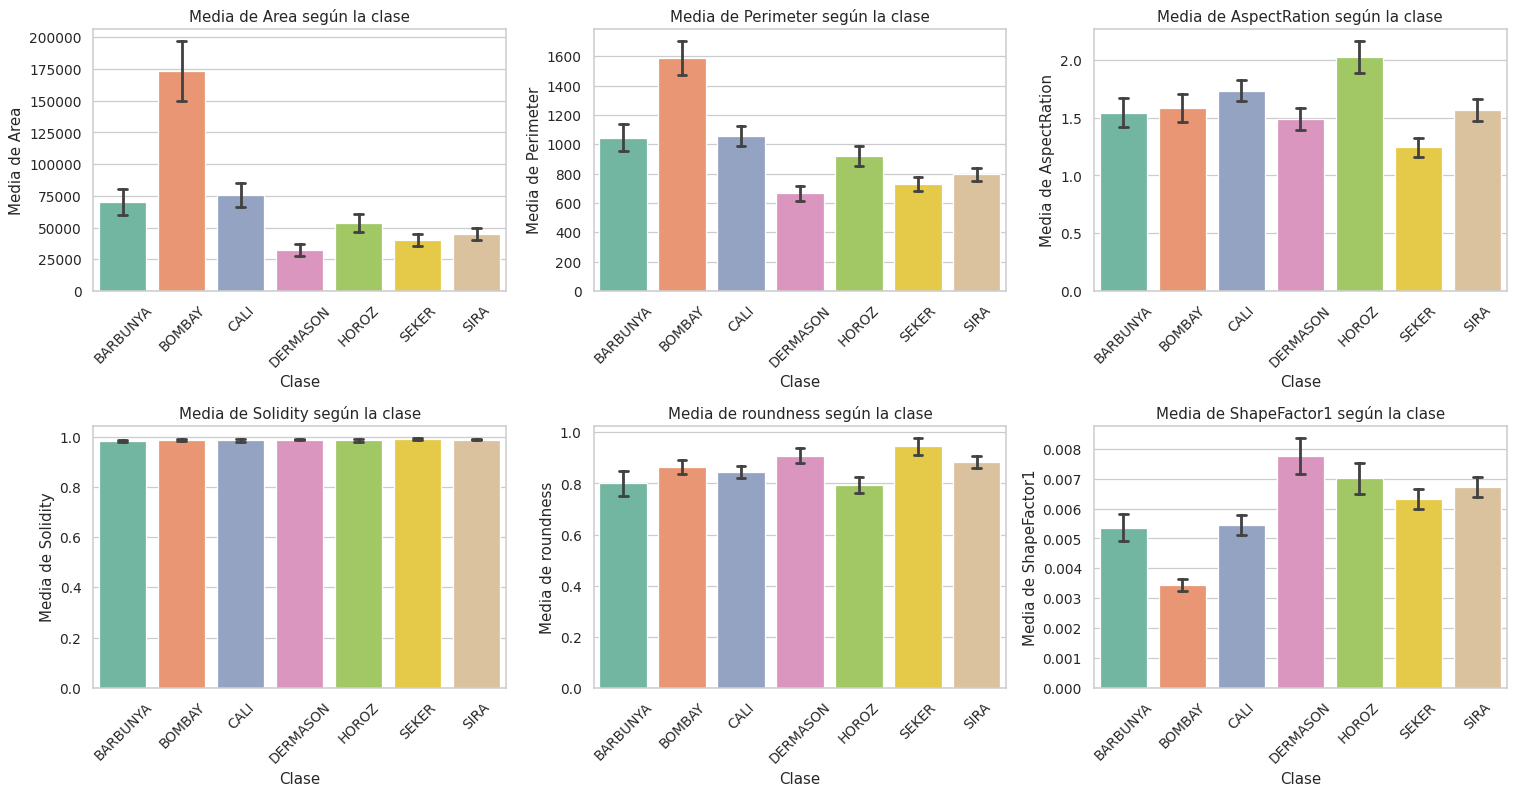

In [ ]:
# Cómo se diferencian las clases en algunas variables clave (tamaño y forma)
clave = ["Area", "Perimeter", "AspectRation", "Solidity", "roundness", "ShapeFactor1"]
orden = sorted(df["Class"].unique())
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), clave):
    sns.barplot(data=df, x="Class", y=col, hue="Class", order=orden, hue_order=orden,
                palette="Set2", legend=False, estimator="mean", errorbar="sd",
                capsize=0.15, ax=ax)
    ax.set_title(f"Media de {col} según la clase")
    ax.set_xlabel("Clase")
    ax.set_ylabel(f"Media de {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

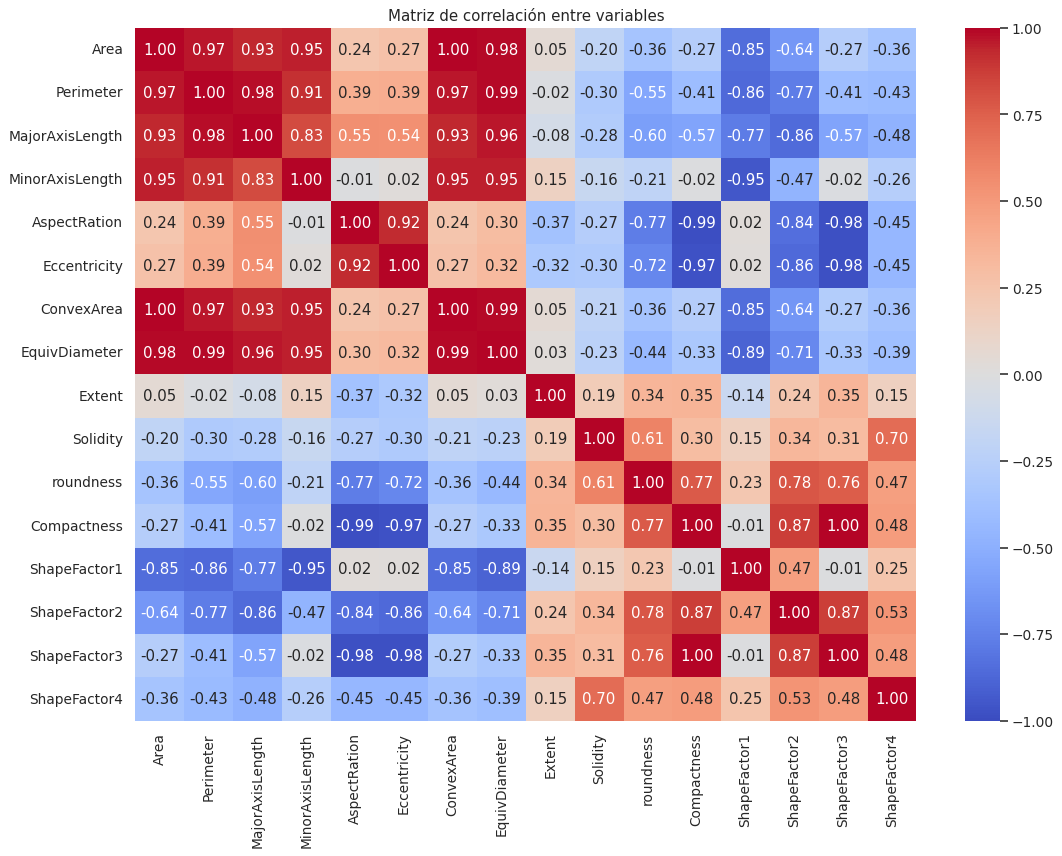

Pares de variables con correlación mayor a 0.95: 15


In [ ]:
# Matriz de correlación: muestra qué variables se parecen entre sí
plt.figure(figsize=(14, 10))
sns.heatmap(df[variables_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación entre variables")
plt.show()

# Cuántos pares de variables son casi idénticas
corr = df[variables_num].corr().abs()
pares = [(a, b) for i, a in enumerate(variables_num) for b in variables_num[i + 1:] if corr.loc[a, b] > 0.95]
print("Pares de variables con correlación mayor a 0.95:", len(pares))


**Qué se observa:**
- Las variables de tamaño separan bien a BOMBAY (granos mucho más grandes) y a DERMASON (los más chicos), y se solapan entre otras clases.
- Muchas variables están muy correlacionadas entre sí. Esto justifica usar PCA (resumir información repetida) y explica por qué la covarianza de QDA es casi singular.
- Varias variables son claramente asimétricas (por ejemplo `Area`, `Solidity` y `ShapeFactor4`), en parte porque mezclan clases de tamaños distintos.


## 8. Preparación y preprocesamiento de los datos


In [ ]:
# Separamos las variables explicativas (X) de la variable a predecir (y), sin modificar el dataframe original
X = df.drop(columns="Class")
y = df["Class"]
clases = sorted(y.unique())          # lista ordenada de clases (se usa en las matrices de confusión)

print("X:", X.shape, "| y:", y.shape)
print("¿Todas las variables son numéricas?", all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes))
print("Clases:", clases)


X: (13611, 16) | y: (13611,)
¿Todas las variables son numéricas? True
Clases: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 9. División en entrenamiento y prueba


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

# Comprobamos que las proporciones de clase se mantienen
proporciones = pd.DataFrame({"Entrenamiento (%)": y_train.value_counts(normalize=True) * 100,
                             "Prueba (%)": y_test.value_counts(normalize=True) * 100}).round(2)
display(proporciones)


Entrenamiento: (9527, 16) | Prueba: (4084, 16)


,Entrenamiento (%),Prueba (%)
Class,,
DERMASON,26.05,26.05
SIRA,19.37,19.37
SEKER,14.89,14.89
HOROZ,14.17,14.15
CALI,11.98,11.97
BARBUNYA,9.71,9.72
BOMBAY,3.83,3.84


In [ ]:
# Los duplicados se conservaron, así que puede haber filas de prueba con una copia exacta en entrenamiento.
# Lo medimos
clave_fila = lambda d: d.round(10).astype(str).agg("|".join, axis=1)
copias = clave_fila(X_test).isin(set(clave_fila(X_train)))
print(f"Filas de prueba con una copia exacta en entrenamiento: {copias.sum()} de {len(X_test)} ({copias.mean() * 100:.2f}%)")

# Validación cruzada de 5 grupos y contenedores de resultados
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos = {}          # acá se guarda cada modelo entrenado
predicciones = {}     # acá se guardan las predicciones sobre el conjunto de prueba


Filas de prueba con una copia exacta en entrenamiento: 31 de 4084 (0.76%)


## 10. Implementación de QDA (Análisis Discriminante Cuadrático)


In [ ]:
# QDA con las variables estandarizadas; el scaler se ajusta solo con entrenamiento
modelos["QDA"] = Pipeline([
    ("scaler", StandardScaler()),
    ("qda", QuadraticDiscriminantAnalysis(tol=1e-10)),   # tol baja: tolera variables casi colineales
])
modelos["QDA"].fit(X_train, y_train)                      # entrenamiento
predicciones["QDA"] = modelos["QDA"].predict(X_test)      # predicción sobre prueba
print(f"QDA - accuracy en prueba: {accuracy_score(y_test, predicciones['QDA']):.4f}")


QDA - accuracy en prueba: 0.9084


## 11. Implementación de SVM (Máquina de Vectores de Soporte)


In [ ]:
# SVM con kernel RBF y variables estandarizadas
modelos["SVM"] = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale")),
])
modelos["SVM"].fit(X_train, y_train)                      # entrenamiento
predicciones["SVM"] = modelos["SVM"].predict(X_test)      # predicción sobre prueba
print(f"SVM - accuracy en prueba: {accuracy_score(y_test, predicciones['SVM']):.4f}")


SVM - accuracy en prueba: 0.9251


## 12. Implementación de PCA (Análisis de Componentes Principales)


In [ ]:
# Ajustamos el escalado y el PCA completo solo con los datos de entrenamiento
scaler_pca = StandardScaler().fit(X_train)
X_train_s = scaler_pca.transform(X_train)
pca_completo = PCA().fit(X_train_s)

# Varianza explicada por cada componente y acumulada
var_exp = pca_completo.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
tabla_pca = pd.DataFrame({"Componente": [f"PC{i + 1}" for i in range(len(var_exp))],
                          "Varianza explicada (%)": (var_exp * 100).round(2),
                          "Varianza acumulada (%)": (var_acum * 100).round(2)})
display(tabla_pca.head(8))

# Cantidad de componentes necesarios para llegar al 95 % de la varianza
n_comp = int(np.argmax(var_acum >= 0.95) + 1)
print(f"Componentes elegidos (95 % de la varianza): {n_comp}")


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,55.46,55.46
1,PC2,26.43,81.89
2,PC3,8.10,89.99
3,PC4,5.09,95.09
4,PC5,2.69,97.78
5,PC6,1.13,98.91
6,PC7,0.70,99.61
7,PC8,0.32,99.93


Componentes elegidos (95 % de la varianza): 4


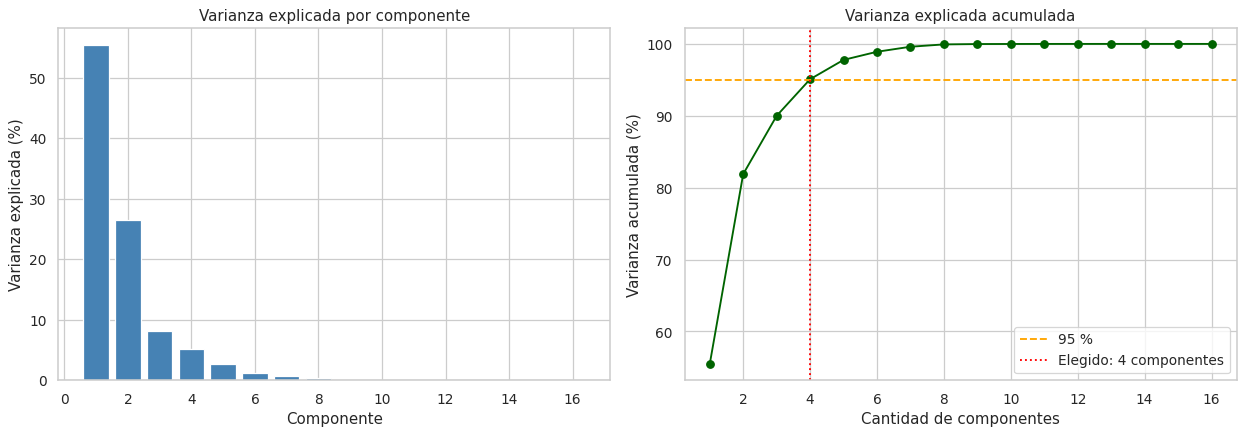

In [ ]:
# Gráfico de codo: varianza por componente y varianza acumulada
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(range(1, len(var_exp) + 1), var_exp * 100, color="steelblue")
ax[0].set_title("Varianza explicada por componente")
ax[0].set_xlabel("Componente")
ax[0].set_ylabel("Varianza explicada (%)")

ax[1].plot(range(1, len(var_acum) + 1), var_acum * 100, marker="o", color="darkgreen")
ax[1].axhline(95, color="orange", linestyle="--", label="95 %")
ax[1].axvline(n_comp, color="red", linestyle=":", label=f"Elegido: {n_comp} componentes")
ax[1].set_title("Varianza explicada acumulada")
ax[1].set_xlabel("Cantidad de componentes")
ax[1].set_ylabel("Varianza acumulada (%)")
ax[1].legend()

plt.tight_layout()
plt.show()


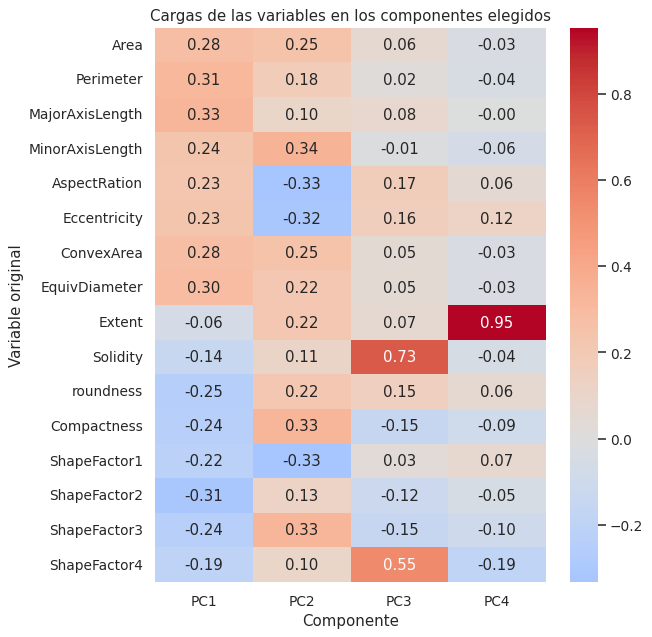

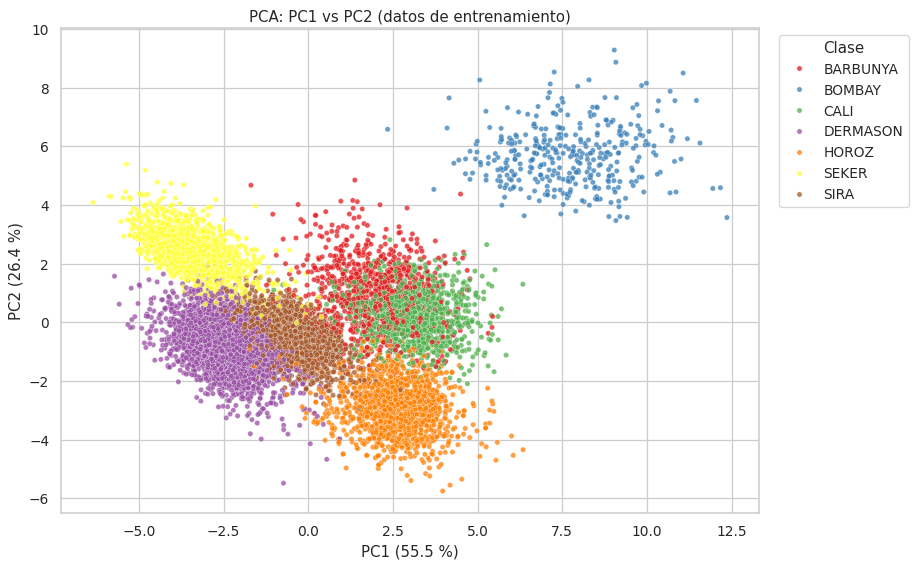

In [ ]:
# Cargas: cuánto pesa cada variable original en cada componente elegido
cargas = pd.DataFrame(pca_completo.components_[:n_comp].T, index=X.columns,
                      columns=[f"PC{i + 1}" for i in range(n_comp)])
plt.figure(figsize=(7, 8))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cargas de las variables en los componentes elegidos")
plt.xlabel("Componente")
plt.ylabel("Variable original")
plt.show()

# Proyección de los datos de entrenamiento en los dos primeros componentes, coloreados por clase
Z = pca_completo.transform(X_train_s)
plt.figure(figsize=(10, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train.values, hue_order=clases, palette="Set1",
                s=18, alpha=0.75, edgecolor="white", linewidth=0.3)
plt.xlabel(f"PC1 ({var_exp[0] * 100:.1f} %)")
plt.ylabel(f"PC2 ({var_exp[1] * 100:.1f} %)")
plt.title("PCA: PC1 vs PC2 (datos de entrenamiento)")
plt.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Interpretación del PCA:**
- Con **4 componentes** se conserva el 95 % de la varianza de las 16 variables: PC1 explica el 55,5 %, PC2 el 26,4 %, PC3 el 8,1 % y PC4 el 5,1 %.
- **PC1** combina el tamaño en oposición a la redondez (`roundness`, `ShapeFactor2`, con signo negativo). **PC2** refleja qué tan alargado es el grano (`AspectRation`, `Eccentricity` y `ShapeFactor1` frente a `MinorAxisLength` y `Compactness`). **PC3** está dominado por `Solidity` y `ShapeFactor4`, y **PC4** casi solo por `Extent`.
- En el gráfico PC1 vs PC2, BOMBAY queda claramente separada por su tamaño, mientras que otras clases se superponen. Esto anticipa que algunas clases parecidas van a ser difíciles de distinguir.
- PC3 y PC4 explican poca varianza, pero pueden contener información útil para separar clases parecidas.


## 13. Implementación de Naive Bayes (NB)


In [ ]:
# Naive Bayes con las 16 variables estandarizadas
modelos["Naive Bayes"] = Pipeline([
    ("scaler", StandardScaler()),
    ("nb", GaussianNB()),
])
modelos["Naive Bayes"].fit(X_train, y_train)
predicciones["Naive Bayes"] = modelos["Naive Bayes"].predict(X_test)

# PCA + Naive Bayes
modelos["PCA + Naive Bayes"] = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp)),
    ("nb", GaussianNB()),
])
modelos["PCA + Naive Bayes"].fit(X_train, y_train)
predicciones["PCA + Naive Bayes"] = modelos["PCA + Naive Bayes"].predict(X_test)

for nombre in ["Naive Bayes", "PCA + Naive Bayes"]:
    print(f"{nombre} - accuracy en prueba: {accuracy_score(y_test, predicciones[nombre]):.4f}")


Naive Bayes - accuracy en prueba: 0.8969
PCA + Naive Bayes - accuracy en prueba: 0.8639


## 14. Implementación de LDA (Análisis Discriminante Lineal)


In [ ]:
# LDA con las variables estandarizadas
modelos["LDA"] = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis()),
])
modelos["LDA"].fit(X_train, y_train)                      # entrenamiento
predicciones["LDA"] = modelos["LDA"].predict(X_test)      # predicción sobre prueba
print(f"LDA - accuracy en prueba: {accuracy_score(y_test, predicciones['LDA']):.4f}")


LDA - accuracy en prueba: 0.9040


## 15. Evaluación y matrices de confusión


In [ ]:
# Orden fijo de los cinco modelos para todas las tablas y gráficos
orden_modelos = ["QDA", "SVM", "Naive Bayes", "PCA + Naive Bayes", "LDA"]

# Métricas en el conjunto de prueba. Precision, recall y F1 son "macro": se calculan por clase y se promedian,
# así todas las clases pesan igual aunque sean de distinto tamaño
filas = []
for nombre in orden_modelos:
    pred = predicciones[nombre]
    filas.append({"Modelo": nombre,
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred, average="macro"),
                  "Recall": recall_score(y_test, pred, average="macro"),
                  "F1-score": f1_score(y_test, pred, average="macro")})
metricas = pd.DataFrame(filas).set_index("Modelo")
display(metricas.round(4))


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
QDA,0.9084,0.9254,0.9259,0.9245
SVM,0.9251,0.9390,0.9359,0.9373
Naive Bayes,0.8969,0.9094,0.9083,0.9078
PCA + Naive Bayes,0.8639,0.8753,0.8680,0.8694
LDA,0.9040,0.9298,0.9173,0.9205


In [ ]:
# Reporte detallado por clase de cada modelo (precision, recall y F1 de cada tipo de poroto)
for nombre in orden_modelos:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, predicciones[nombre], digits=3))


===== QDA =====
              precision    recall  f1-score   support

    BARBUNYA      0.946     0.884     0.914       397
      BOMBAY      1.000     1.000     1.000       157
        CALI      0.924     0.947     0.935       489
    DERMASON      0.945     0.838     0.888      1064
       HOROZ      0.941     0.958     0.949       578
       SEKER      0.925     0.947     0.936       608
        SIRA      0.798     0.906     0.849       791

    accuracy                          0.908      4084
   macro avg      0.925     0.926     0.925      4084
weighted avg      0.912     0.908     0.909      4084

===== SVM =====
              precision    recall  f1-score   support

    BARBUNYA      0.955     0.899     0.926       397
      BOMBAY      1.000     1.000     1.000       157
        CALI      0.943     0.947     0.945       489
    DERMASON      0.918     0.913     0.915      1064
       HOROZ      0.957     0.969     0.963       578
       SEKER      0.938     0.944     0.941   

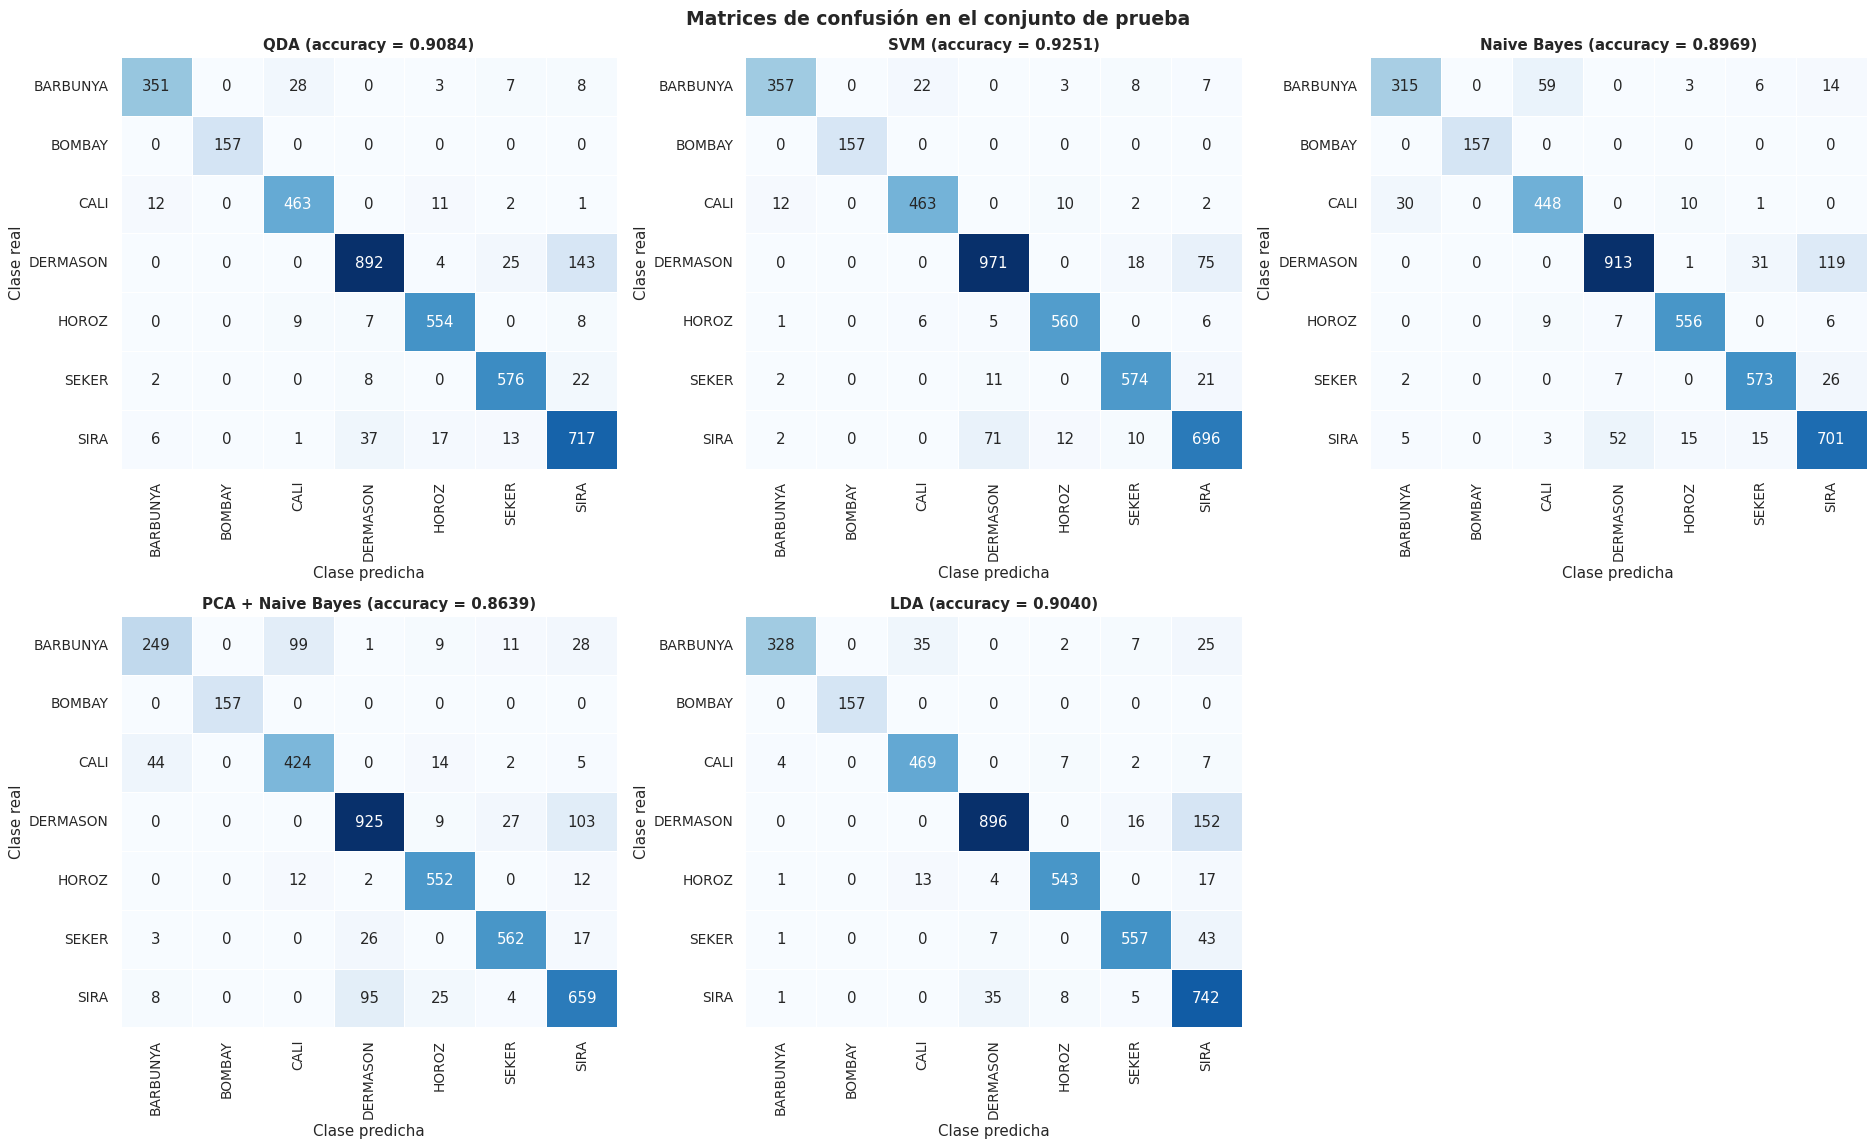

In [ ]:
# Matrices de confusión de los cinco modelos
fig, axes = plt.subplots(2, 3, figsize=(21, 13))
for ax, nombre in zip(axes.ravel(), orden_modelos):
    cm = confusion_matrix(y_test, predicciones[nombre], labels=clases)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5,
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(f"{nombre} (accuracy = {metricas.loc[nombre, 'Accuracy']:.4f})", fontweight="bold")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
axes.ravel()[-1].axis("off")          # el sexto casillero queda vacío (hay cinco modelos)
plt.suptitle("Matrices de confusión en el conjunto de prueba", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


**Interpretación de cada modelo** (conjunto de prueba: 4.084 granos):
- **QDA** (accuracy 0,908): su error principal es confundir DERMASON con SIRA (143 de 1.064 granos de DERMASON). También confunde algunos BARBUNYA con CALI (28).
- **SVM** (accuracy 0,925): es el que menos errores comete. Mantiene la confusión DERMASON/SIRA, pero más repartida entre ambos sentidos (75 y 71 granos), y reconoce mejor a BARBUNYA (recall 0,90).
- **Naive Bayes** (accuracy 0,897): confunde más BARBUNYA con CALI (59 granos) y DERMASON con SIRA (119). Su suposición de variables independientes no se cumple, porque muchas variables están muy correlacionadas.
- **PCA + Naive Bayes** (accuracy 0,864): es el de peor desempeño. Su recall de BARBUNYA cae a 0,63 (99 de 397 granos se predicen como CALI). Perder 12 de las 16 dimensiones le hace perder información que sí servía para separar clases parecidas.
- **LDA** (accuracy 0,904): sus fronteras rectas no alcanzan para DERMASON/SIRA (152 granos de DERMASON predichos como SIRA) y además confunde SEKER con SIRA (43). Acierta mucho en SIRA (recall 0,94) a costa de DERMASON.
- **BOMBAY** se clasifica perfecto (recall 1,00) en los cinco modelos: sus granos son mucho más grandes que los del resto.


## 16. Comparación de resultados


In [ ]:
# Validación cruzada de 5 grupos SOLO sobre entrenamiento: mide si el resultado es estable y no depende de una sola partición
filas_cv = []
for nombre in orden_modelos:
    puntajes = cross_val_score(modelos[nombre], X_train, y_train, cv=cv, scoring="accuracy")
    filas_cv.append({"Modelo": nombre, "Accuracy CV (media)": puntajes.mean(), "Accuracy CV (desvío)": puntajes.std()})
comparacion = metricas.join(pd.DataFrame(filas_cv).set_index("Modelo")).sort_values("F1-score", ascending=False)
display(comparacion.round(4))

mejor = comparacion["F1-score"].idxmax()
print(f"Mejor modelo según F1-score macro: {mejor} (F1 = {comparacion.loc[mejor, 'F1-score']:.4f}, accuracy = {comparacion.loc[mejor, 'Accuracy']:.4f})")


,Accuracy,Precision,Recall,F1-score,Accuracy CV (media),Accuracy CV (desvío)
Modelo,,,,,,
SVM,0.9251,0.9390,0.9359,0.9373,0.9312,0.0049
QDA,0.9084,0.9254,0.9259,0.9245,0.9137,0.0051
LDA,0.9040,0.9298,0.9173,0.9205,0.9046,0.0055
Naive Bayes,0.8969,0.9094,0.9083,0.9078,0.8973,0.0068
PCA + Naive Bayes,0.8639,0.8753,0.8680,0.8694,0.8625,0.0076


Mejor modelo según F1-score macro: SVM (F1 = 0.9373, accuracy = 0.9251)


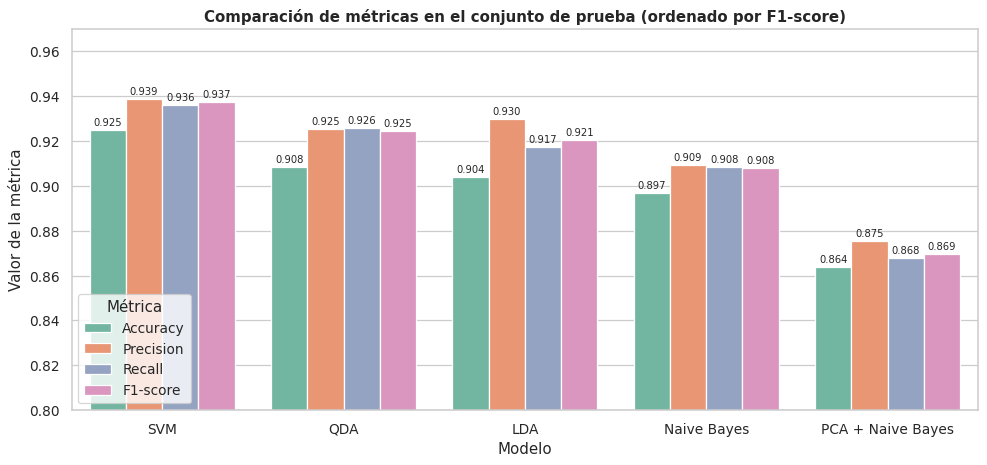

In [ ]:
# Comparación gráfica de las cuatro métricas de los cinco modelos
largo = metricas.loc[comparacion.index].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
plt.figure(figsize=(13, 5.5))
ax = sns.barplot(data=largo, x="Modelo", y="Valor", hue="Métrica", palette="Set2")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", fontsize=8, padding=2)
plt.ylim(0.8, 0.97)
plt.title("Comparación de métricas en el conjunto de prueba (ordenado por F1-score)", fontweight="bold")
plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.legend(title="Métrica", loc="lower left")
plt.show()


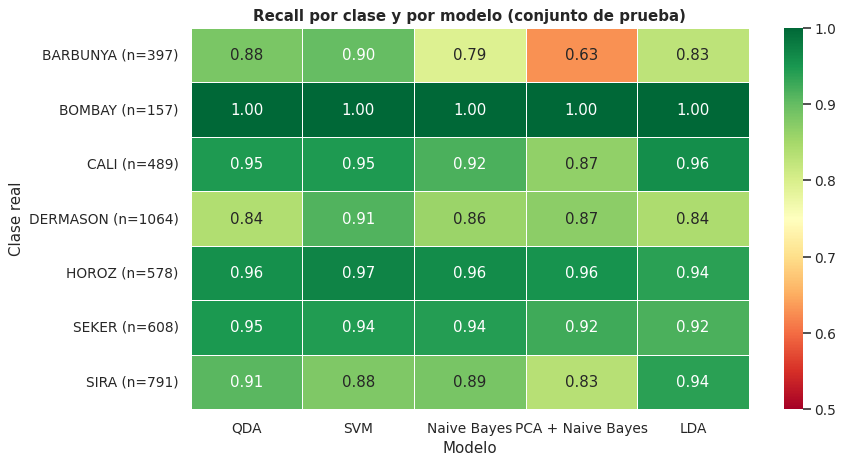

In [ ]:
# Recall de cada clase por modelo: muestra qué tipos de poroto acierta o falla cada algoritmo

recall_clase = pd.DataFrame({nombre: recall_score(y_test, predicciones[nombre], labels=clases, average=None)
                             for nombre in orden_modelos}, index=clases)
recall_clase.index = [f"{c} (n={(y_test == c).sum()})" for c in clases]

plt.figure(figsize=(10, 5.5))
sns.heatmap(recall_clase, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1, linewidths=0.5)
plt.title("Recall por clase y por modelo (conjunto de prueba)", fontweight="bold")
plt.xlabel("Modelo")
plt.ylabel("Clase real")
plt.show()


## 17. PCA aplicado a todos los algoritmos: comparación con y sin PCA

Hasta acá PCA se probó solo con Naive Bayes. En esta sección se aplica a los cuatro clasificadores (LDA, QDA, Naive Bayes y SVM) y se compara cada uno **sin PCA**  contra **con PCA**.

Cómo se arma la comparación (para que sea justa):
- Misma partición entrenamiento/prueba y misma validación cruzada que en las secciones anteriores.
- Cada modelo con PCA es un `Pipeline`: estandarizar → PCA → clasificador. El escalado y el PCA se ajustan solo con entrenamiento.
- Se usa la misma cantidad de componentes y los clasificadores conservan los mismos hiperparámetros que en su versión sin PCA.
- Naive Bayes + PCA es el modelo de la sección 13


In [ ]:
# Versión CON PCA de cada algoritmo: estandarizar -> PCA -> clasificador.
# Todo se ajusta solo con los datos de entrenamiento (lo hace el Pipeline al hacer fit).
modelos["QDA + PCA"] = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp)),
    ("qda", QuadraticDiscriminantAnalysis(tol=1e-10)),
])
modelos["SVM + PCA"] = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp)),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale")),          # mismos hiperparámetros que el SVM sin PCA
])
modelos["LDA + PCA"] = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp)),
    ("lda", LinearDiscriminantAnalysis()),
])

for nombre in ["QDA + PCA", "SVM + PCA", "LDA + PCA"]:
    modelos[nombre].fit(X_train, y_train)                    # entrenamiento
    predicciones[nombre] = modelos[nombre].predict(X_test)   # predicción sobre prueba

# Naive Bayes + PCA ya se entrenó en la sección 13
modelos["Naive Bayes + PCA"] = modelos["PCA + Naive Bayes"]
predicciones["Naive Bayes + PCA"] = predicciones["PCA + Naive Bayes"]

print(f"Componentes usados en todos los modelos con PCA: {n_comp}\n")
for nombre in ["QDA + PCA", "SVM + PCA", "Naive Bayes + PCA", "LDA + PCA"]:
    print(f"{nombre} - accuracy en prueba: {accuracy_score(y_test, predicciones[nombre]):.4f}")


Componentes usados en todos los modelos con PCA: 4

QDA + PCA - accuracy en prueba: 0.8866
SVM + PCA - accuracy en prueba: 0.8962
Naive Bayes + PCA - accuracy en prueba: 0.8639
LDA + PCA - accuracy en prueba: 0.8825


### 17.1 Métricas: cada algoritmo sin PCA vs con PCA


In [ ]:
# Pares (algoritmo sin PCA -> algoritmo con PCA)
pares = {"QDA": "QDA + PCA", "SVM": "SVM + PCA", "Naive Bayes": "Naive Bayes + PCA", "LDA": "LDA + PCA"}

# Métricas en prueba (macro) y validación cruzada de 5 grupos sobre entrenamiento, para las 8 versiones
filas = []
for base, con in pares.items():
    for nombre, version in [(base, "Sin PCA"), (con, "Con PCA")]:
        pred = predicciones[nombre]
        puntajes = cross_val_score(modelos[nombre], X_train, y_train, cv=cv, scoring="accuracy")
        filas.append({"Algoritmo": base, "Versión": version,
                      "Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred, average="macro"),
                      "Recall": recall_score(y_test, pred, average="macro"),
                      "F1-score": f1_score(y_test, pred, average="macro"),
                      "Accuracy CV (media)": puntajes.mean(),
                      "Accuracy CV (desvío)": puntajes.std()})
comp_pca = pd.DataFrame(filas).set_index(["Algoritmo", "Versión"])
display(comp_pca.round(4))

# Diferencia (Con PCA - Sin PCA): positivo = PCA mejora, negativo = PCA empeora
columnas = ["Accuracy", "Precision", "Recall", "F1-score", "Accuracy CV (media)"]
dif = pd.DataFrame({base: comp_pca.loc[(base, "Con PCA"), columnas] - comp_pca.loc[(base, "Sin PCA"), columnas]
                    for base in pares}).T
print("\nDiferencia (Con PCA - Sin PCA):")
display(dif.round(4))


Accuracy  Precision  Recall  F1-score  \
Algoritmo   Versión                                          
QDA         Sin PCA    0.9084     0.9254  0.9259    0.9245   
            Con PCA    0.8866     0.8923  0.8910    0.8906   
SVM         Sin PCA    0.9251     0.9390  0.9359    0.9373   
            Con PCA    0.8962     0.9040  0.8967    0.8989   
Naive Bayes Sin PCA    0.8969     0.9094  0.9083    0.9078   
            Con PCA    0.8639     0.8753  0.8680    0.8694   
LDA         Sin PCA    0.9040     0.9298  0.9173    0.9205   
            Con PCA    0.8825     0.8930  0.8850    0.8868   

                     Accuracy CV (media)  Accuracy CV (desvío)  
Algoritmo   Versión                                             
QDA         Sin PCA               0.9137                0.0051  
            Con PCA               0.8856                0.0057  
SVM         Sin PCA               0.9312                0.0049  
            Con PCA               0.8926                0.0031  
Naive Bayes Sin PCA               0.8973                0.0068  
            Con PCA               0.8625                0.0076  
LDA         Sin PCA               0.9046                0.0055  
            Con PCA               0.8783                0.0070


Diferencia (Con PCA - Sin PCA):


,Accuracy,Precision,Recall,F1-score,Accuracy CV (media)
QDA,-0.0218,-0.0331,-0.0349,-0.0340,-0.0281
SVM,-0.0289,-0.0350,-0.0392,-0.0384,-0.0386
Naive Bayes,-0.0331,-0.0341,-0.0403,-0.0384,-0.0348
LDA,-0.0215,-0.0368,-0.0323,-0.0337,-0.0262


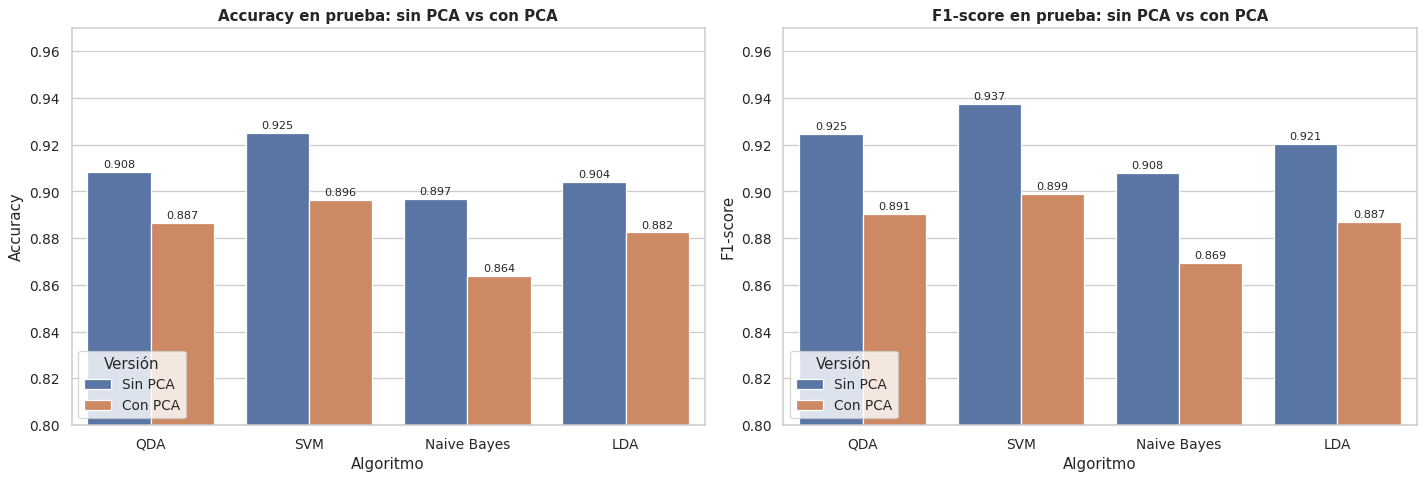

In [ ]:
# Gráfico: para cada algoritmo, barra sin PCA vs barra con PCA
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metrica in zip(axes, ["Accuracy", "F1-score"]):
    datos = comp_pca[metrica].reset_index()
    sns.barplot(data=datos, x="Algoritmo", y=metrica, hue="Versión", hue_order=["Sin PCA", "Con PCA"],
                palette=["#4C72B0", "#DD8452"], ax=ax)
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt="%.3f", fontsize=9, padding=2)
    ax.set_ylim(0.8, 0.97)
    ax.set_title(f"{metrica} en prueba: sin PCA vs con PCA", fontweight="bold")
    ax.set_xlabel("Algoritmo")
    ax.set_ylabel(metrica)
    ax.legend(title="Versión", loc="lower left")
plt.tight_layout()
plt.show()


### 17.2 Errores por clase: matrices de confusión y cambio en el recall


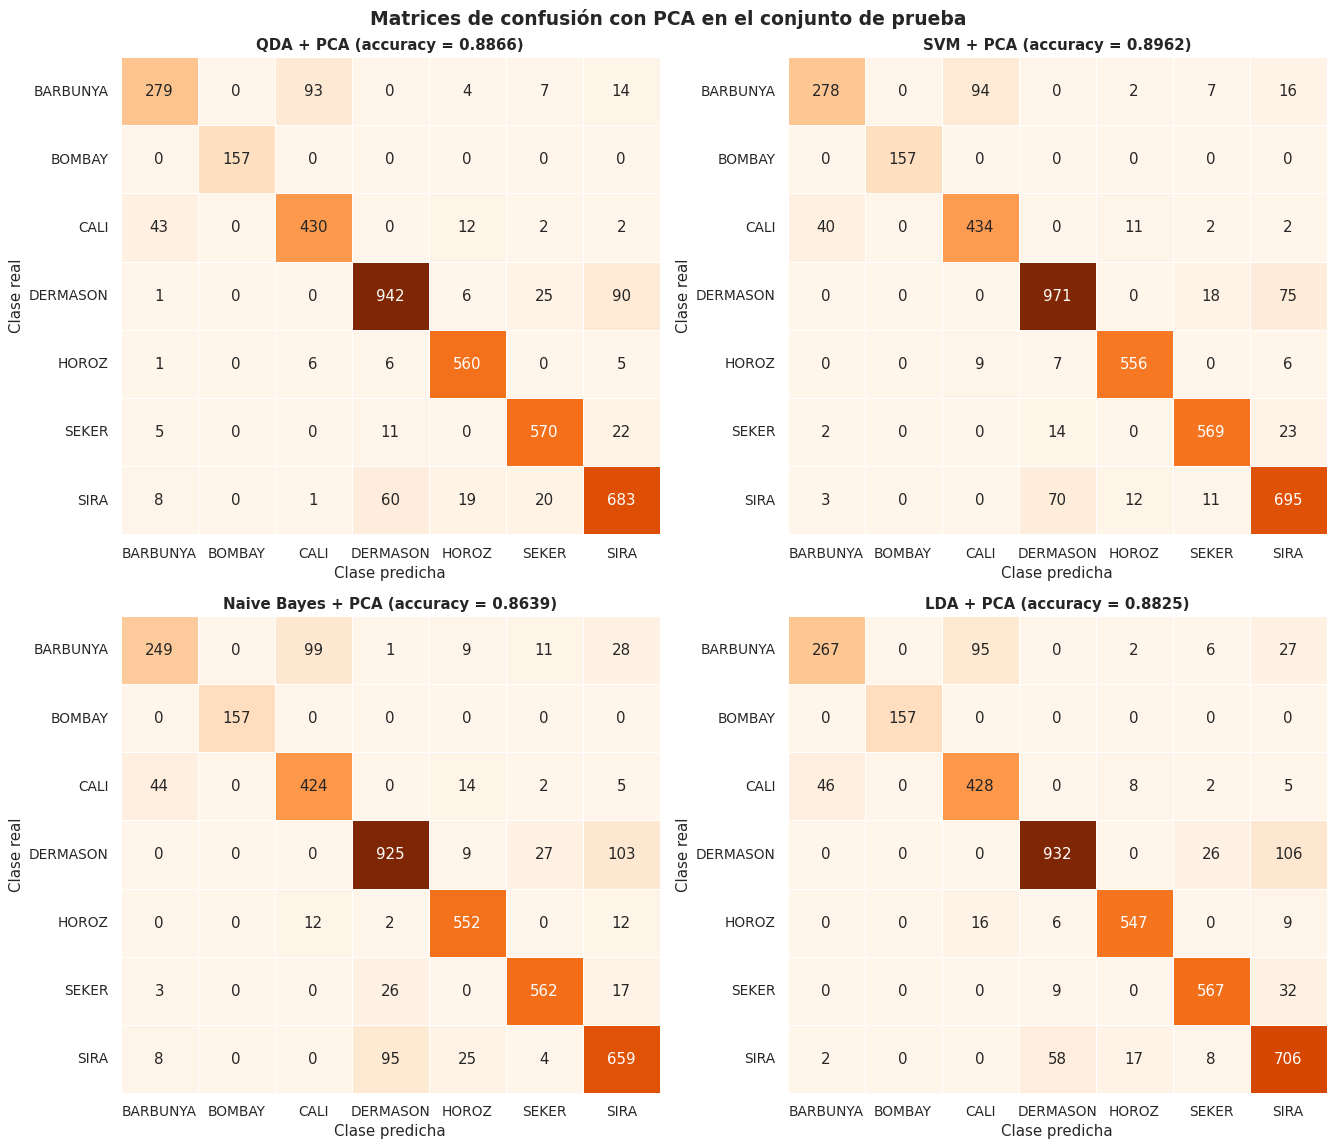

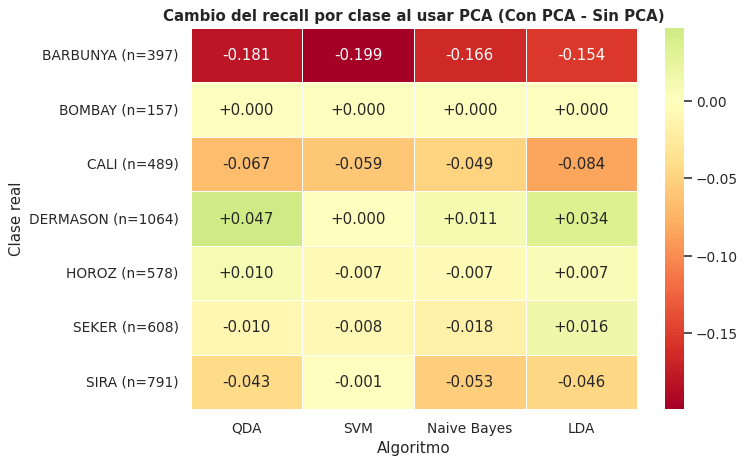

In [ ]:
# Matrices de confusión de los cuatro modelos CON PCA
orden_pca = ["QDA + PCA", "SVM + PCA", "Naive Bayes + PCA", "LDA + PCA"]
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for ax, nombre in zip(axes.ravel(), orden_pca):
    cm = confusion_matrix(y_test, predicciones[nombre], labels=clases)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False, linewidths=0.5,
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(f"{nombre} (accuracy = {accuracy_score(y_test, predicciones[nombre]):.4f})", fontweight="bold")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión con PCA en el conjunto de prueba", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Cambio en el recall de cada clase al agregar PCA (Con PCA - Sin PCA): verde = mejora, rojo = empeora
def recall_por_clase(nombre):
    return recall_score(y_test, predicciones[nombre], labels=clases, average=None)

dif_recall = pd.DataFrame({base: recall_por_clase(con) - recall_por_clase(base) for base, con in pares.items()},
                          index=[f"{c} (n={(y_test == c).sum()})" for c in clases])
plt.figure(figsize=(8, 5.5))
sns.heatmap(dif_recall, annot=True, fmt="+.3f", cmap="RdYlGn", center=0, linewidths=0.5)
plt.title("Cambio del recall por clase al usar PCA (Con PCA - Sin PCA)", fontweight="bold")
plt.xlabel("Algoritmo")
plt.ylabel("Clase real")
plt.show()


,QDA,SVM,Naive Bayes,LDA
Componentes,,,,
2,0.8698,0.8706,0.8545,0.8642
3,0.8757,0.8824,0.8561,0.8685
4,0.8856,0.8926,0.8625,0.8783
6,0.9181,0.9296,0.8998,0.9069
8,0.9162,0.9312,0.8968,0.8982
10,0.9147,0.9312,0.8910,0.8962
12,0.9128,0.9312,0.8887,0.9004
16,0.9137,0.9312,0.8788,0.9046


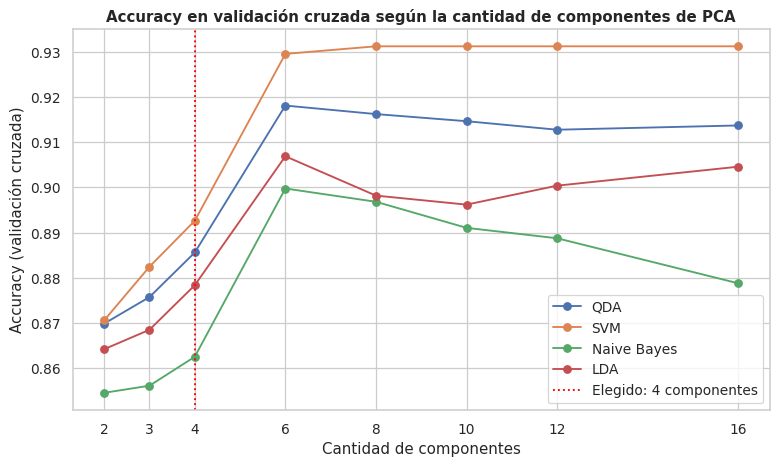

In [ ]:
# Accuracy en validación cruzada (solo entrenamiento) según la cantidad de componentes del PCA
lista_comp = [2, 3, 4, 6, 8, 10, 12, 16]
fabricas = {
    "QDA": lambda: QuadraticDiscriminantAnalysis(tol=1e-10),
    "SVM": lambda: SVC(kernel="rbf", C=1, gamma="scale"),
    "Naive Bayes": lambda: GaussianNB(),
    "LDA": lambda: LinearDiscriminantAnalysis(),
}

sensibilidad = {}
for algoritmo, fabrica in fabricas.items():
    medias = []
    for k in lista_comp:
        pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", fabrica())])
        medias.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean())
    sensibilidad[algoritmo] = medias
sens = pd.DataFrame(sensibilidad, index=lista_comp)
sens.index.name = "Componentes"
display(sens.round(4))

plt.figure(figsize=(10, 5.5))
for algoritmo in sens.columns:
    plt.plot(sens.index, sens[algoritmo], marker="o", label=algoritmo)
plt.axvline(n_comp, color="red", linestyle=":", label=f"Elegido: {n_comp} componentes")
plt.title("Accuracy en validación cruzada según la cantidad de componentes de PCA", fontweight="bold")
plt.xlabel("Cantidad de componentes")
plt.ylabel("Accuracy (validación cruzada)")
plt.xticks(lista_comp)
plt.legend()
plt.show()


### 17.4 Resumen y conclusión de la comparación con y sin PCA


In [ ]:
# Veredicto automático para cada algoritmo (se calcula con los resultados de esta misma ejecución)
umbral = 0.002   # diferencias menores a 0,2 puntos de accuracy se consideran "prácticamente iguales"
print("Efecto de PCA en cada algoritmo (conjunto de prueba):\n")
for base in pares:
    sin_acc, con_acc = comp_pca.loc[(base, "Sin PCA"), "Accuracy"], comp_pca.loc[(base, "Con PCA"), "Accuracy"]
    sin_f1, con_f1 = comp_pca.loc[(base, "Sin PCA"), "F1-score"], comp_pca.loc[(base, "Con PCA"), "F1-score"]
    d = con_acc - sin_acc
    veredicto = "PCA MEJORA" if d > umbral else ("PCA EMPEORA" if d < -umbral else "PCA casi no cambia el resultado")
    print(f"{base:12s} accuracy {sin_acc:.4f} -> {con_acc:.4f} ({d * 100:+.2f} pts) | "
          f"F1 {sin_f1:.4f} -> {con_f1:.4f} ({(con_f1 - sin_f1) * 100:+.2f} pts) | {veredicto}")

# Ranking de las 8 versiones juntas
ranking = comp_pca.reset_index()
ranking["Modelo"] = ranking.apply(lambda r: r["Algoritmo"] if r["Versión"] == "Sin PCA" else r["Algoritmo"] + " + PCA", axis=1)
ranking = ranking.set_index("Modelo")[["Accuracy", "Precision", "Recall", "F1-score", "Accuracy CV (media)"]]
ranking = ranking.sort_values("F1-score", ascending=False)
print("\nRanking de las 8 versiones (ordenado por F1-score macro):")
display(ranking.round(4))
print(f"Mejor de las 8 versiones: {ranking.index[0]} (F1 = {ranking['F1-score'].iloc[0]:.4f}, accuracy = {ranking['Accuracy'].iloc[0]:.4f})")


Efecto de PCA en cada algoritmo (conjunto de prueba):

QDA          accuracy 0.9084 -> 0.8866 (-2.18 pts) | F1 0.9245 -> 0.8906 (-3.40 pts) | PCA EMPEORA
SVM          accuracy 0.9251 -> 0.8962 (-2.89 pts) | F1 0.9373 -> 0.8989 (-3.84 pts) | PCA EMPEORA
Naive Bayes  accuracy 0.8969 -> 0.8639 (-3.31 pts) | F1 0.9078 -> 0.8694 (-3.84 pts) | PCA EMPEORA
LDA          accuracy 0.9040 -> 0.8825 (-2.15 pts) | F1 0.9205 -> 0.8868 (-3.37 pts) | PCA EMPEORA

Ranking de las 8 versiones (ordenado por F1-score macro):


,Accuracy,Precision,Recall,F1-score,Accuracy CV (media)
Modelo,,,,,
SVM,0.9251,0.9390,0.9359,0.9373,0.9312
QDA,0.9084,0.9254,0.9259,0.9245,0.9137
LDA,0.9040,0.9298,0.9173,0.9205,0.9046
Naive Bayes,0.8969,0.9094,0.9083,0.9078,0.8973
SVM + PCA,0.8962,0.9040,0.8967,0.8989,0.8926
QDA + PCA,0.8866,0.8923,0.8910,0.8906,0.8856
LDA + PCA,0.8825,0.8930,0.8850,0.8868,0.8783
Naive Bayes + PCA,0.8639,0.8753,0.8680,0.8694,0.8625


Mejor de las 8 versiones: SVM (F1 = 0.9373, accuracy = 0.9251)


**Conclusión de la comparación con y sin PCA** (conjunto de prueba, 4.084 granos, 4 componentes):

| Algoritmo | Accuracy sin PCA | Accuracy con PCA | Diferencia | F1 sin PCA | F1 con PCA |
|---|---|---|---|---|---|
| QDA | 0,908 | 0,887 | -2,2 pts | 0,925 | 0,891 |
| SVM | 0,925 | 0,896 | -2,9 pts | 0,937 | 0,899 |
| Naive Bayes | 0,897 | 0,864 | -3,3 pts | 0,908 | 0,869 |
| LDA | 0,904 | 0,883 | -2,2 pts | 0,921 | 0,887 |

- **PCA con 4 componentes empeora a los cuatro algoritmos**, y lo hace de forma pareja: entre 2,2 y 3,3 puntos de accuracy y unos 3,4 a 3,8 puntos de F1. La validación cruzada sobre entrenamiento muestra la misma caída (entre 2,6 y 3,9 puntos), así que no es un efecto de la partición.
- **El orden de los modelos casi no cambia**: SVM sigue siendo el mejor con y sin PCA, y Naive Bayes el peor. De hecho, SVM + PCA (0,896) queda a la par de Naive Bayes sin PCA (0,897). Ninguna versión con PCA supera a su versión original, y el mejor de los ocho modelos es SVM sin PCA.
- **Naive Bayes es el que más pierde (-3,3 pts)**, aunque en teoría es el que más debería beneficiarse de componentes decorrelacionados. Que igual empeore indica que, con 4 componentes, el costo de perder información pesa más que el beneficio de acercarse a la suposición de independencia.
- **La causa es la cantidad de componentes, no PCA en sí.** En la sección 17.3 (validación cruzada) todos los algoritmos mejoran mucho al pasar de 4 a 6 componentes: SVM llega a 0,930, igual que con las 16 variables (0,931), y QDA (0,918), Naive Bayes (0,900) y LDA (0,907) igualan o superan levemente a su versión sin PCA (0,914, 0,897 y 0,905; en QDA y LDA la diferencia está dentro del desvío de la validación cruzada, cerca de 0,5 puntos). Las componentes 5 y 6 explican poca varianza, pero aportan información que sirve para separar clases parecidas como DERMASON/SIRA. El criterio del 95 % de varianza resultó demasiado agresivo para este problema.
- **Matiz sobre el punto anterior:** el barrido de 17.3 usa validación cruzada sobre entrenamiento y es exploratorio; la comparación principal de este examen sigue siendo la de 4 componentes. Si se quisiera usar PCA en la práctica, convendría fijar la cantidad de componentes por validación cruzada y no por el porcentaje de varianza.


## 18. Conclusiones finales


**Mejor modelo: SVM.** Tiene el mejor valor en las cuatro métricas del conjunto de prueba (accuracy 0,925, precision 0,939, recall 0,936 y F1-score 0,937) y también el mejor accuracy en validación cruzada sobre entrenamiento (0,931 ± 0,005). Le siguen QDA (F1 0,925), LDA (0,921) y Naive Bayes (0,908). Las versiones con PCA quedan todas por debajo de su versión original: SVM + PCA (0,899), QDA + PCA (0,891), LDA + PCA (0,887) y, última, Naive Bayes + PCA (0,869). La diferencia entre SVM y QDA (cerca de 1,7 puntos de accuracy) es mayor que el desvío de la validación cruzada (0,5 puntos), por lo que no parece producto del azar de la partición.

**Qué aprendimos de los resultados:**
1. **El tipo de frontera importa.** SVM (frontera curva y flexible) supera a QDA (curva, pero con suposición de normalidad) y a LDA (recta). Los modelos más simples (NB y LDA) quedan por debajo.
2. **PCA con 4 componentes empeoró a los cuatro algoritmos.** Al aplicar PCA (95 % de la varianza, 4 componentes) a LDA, QDA, Naive Bayes y SVM, el accuracy bajó entre 2,2 y 3,3 puntos en todos (QDA 0,908 → 0,887; SVM 0,925 → 0,896; Naive Bayes 0,897 → 0,864; LDA 0,904 → 0,883) y el F1-score macro entre 3,4 y 3,8 puntos. La validación cruzada muestra la misma caída, así que no depende de la partición. El orden de los modelos casi no cambia: SVM sigue siendo el mejor con y sin PCA, y ninguna versión con PCA supera a su versión original.
3. **Los errores están en clases parecidas**, no en las clases chicas: todos los modelos confunden DERMASON con SIRA y BARBUNYA con CALI, mientras que BOMBAY (la clase más chica) se acierta siempre.

**Por qué PCA no ayudó acá:** el problema no es PCA en sí, sino la cantidad de componentes. Las componentes 5 y 6 explican poca varianza, pero aportan información útil para separar clases parecidas (como DERMASON/SIRA). En el barrido de la sección 17.3 (validación cruzada), con 6 componentes SVM llega a 0,930 (igual que sin PCA, 0,931) y QDA, LDA y Naive Bayes igualan o superan levemente a sus versiones originales. Por eso el criterio del 95 % de varianza resultó demasiado agresivo para este dataset. Naive Bayes fue el que más perdió con 4 componentes (-3,3 puntos), aunque en teoría es el que más se beneficia de variables decorrelacionadas: acá pesó más la información perdida que la mejora en la suposición de independencia. Si se usara PCA en la práctica, conviene definir la cantidad de componentes por validación cruzada y no por el porcentaje de varianza.
